# Online Retail II: Data Loading and Initial Inspection

## Objective

The objective of this notebook is to load the Online Retail II
dataset, combine both Excel worksheets, and understand the
structure and quality of the raw transaction data.

## Business Context

The retailer wants to understand its revenue performance,
customer behaviour, and potential revenue leakage.

Before analysing the business, we need to inspect the data
and identify quality issues that may affect our conclusions.

In [17]:
import pandas as pd
from pathlib import Path

project_root = Path.cwd().parent

file_path = project_root / "data" / "raw" / "online_retail_II.xlsx"
print("File exists:", file_path.exists())
print("File path:", file_path)

File exists: True
File path: /Users/khooshimangal/retail-revenue-retention-analysis/data/raw/online_retail_II.xlsx


In [18]:
excel_file = pd.ExcelFile(file_path)
print("Excel sheet names:")
print(excel_file.sheet_names)

Excel sheet names:
['Year 2009-2010', 'Year 2010-2011']


In [20]:
all_sheets = pd.read_excel(file_path, sheet_name = None)

In [12]:
print(type(all_sheets))

<class 'dict'>


In [21]:
print(all_sheets.keys())

dict_keys(['Year 2009-2010', 'Year 2010-2011'])


In [22]:
print(all_sheets.items())

dict_items([('Year 2009-2010',        Invoice StockCode                          Description  Quantity  \
0       489434     85048  15CM CHRISTMAS GLASS BALL 20 LIGHTS        12   
1       489434    79323P                   PINK CHERRY LIGHTS        12   
2       489434    79323W                  WHITE CHERRY LIGHTS        12   
3       489434     22041         RECORD FRAME 7" SINGLE SIZE         48   
4       489434     21232       STRAWBERRY CERAMIC TRINKET BOX        24   
...        ...       ...                                  ...       ...   
525456  538171     22271                 FELTCRAFT DOLL ROSIE         2   
525457  538171     22750         FELTCRAFT PRINCESS LOLA DOLL         1   
525458  538171     22751       FELTCRAFT PRINCESS OLIVIA DOLL         1   
525459  538171     20970   PINK FLORAL FELTCRAFT SHOULDER BAG         2   
525460  538171     21931               JUMBO STORAGE BAG SUKI         2   

               InvoiceDate  Price  Customer ID         Country  
0  

In [23]:
for sheet_name, df in all_sheets.items():
    print(sheet_name, df.shape)

Year 2009-2010 (525461, 8)
Year 2010-2011 (541910, 8)


In [24]:
combined_df = pd.concat(
    all_sheets.values(),
    ignore_index = True
)

print("Combined data shape:", combined_df.shape)

Combined data shape: (1067371, 8)


In [25]:
csv_path = (
    project_root
    / "data"
    / "processed"
    / "online_retail_II_combined.csv"
)

combined_df.to_csv(csv_path, index = False)

print("CSV saved successfully")
print(csv_path)

CSV saved successfully
/Users/khooshimangal/retail-revenue-retention-analysis/data/processed/online_retail_II_combined.csv


In [26]:
combined_df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [27]:
print("Dataset shape:", combined_df.shape)
print("\nColumn names:")
print(combined_df.columns.tolist())

Dataset shape: (1067371, 8)

Column names:
['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']


In [29]:
print(combined_df.dtypes)

Invoice                object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
Price                 float64
Customer ID           float64
Country                object
dtype: object


In [32]:
missing_summary = pd.DataFrame({
    "Missing_Count": combined_df.isna().sum(),
    "Missing_Percentage": combined_df.isna().mean() * 100
})
missing_summary = missing_summary.sort_values(
    "Missing_Percentage",
    ascending = False
)

display(missing_summary)

,Missing_Count,Missing_Percentage
Customer ID,243007,22.766873
Description,4382,0.410541
Invoice,0,0.000000
StockCode,0,0.000000
Quantity,0,0.000000
InvoiceDate,0,0.000000
Price,0,0.000000
Country,0,0.000000


In [34]:
duplicate_count = combined_df.duplicated().sum()
print("Fully duplicated rows:", duplicate_count)

Fully duplicated rows: 34335


In [35]:
display(combined_df.head())

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


## Initial Data Observations

1. Missing Data: Approximately 22.77% of rows lack a Customer ID, limiting our ability to analyse customer retention and customer lifetime value accurately. However, these transactions may still be useful for revenue analysis.

2. Duplicate Records: The dataset contains 34,335 fully duplicated rows. We need to investigate these records and measure their impact before deciding whether to remove them, as they may affect transaction counts and revenue calculations.

3. Data Types: The InvoiceDate column is correctly stored as a datetime, while Customer ID is stored as a float. Since Customer ID is an identifier rather than a numerical measure, we should investigate an appropriate data type for future customer analysis.

In [38]:
invoice_text = combined_df["Invoice"].astype("string")
cancellation_mask = invoice_text.str.startswith(
    "C",
    na = False
)
cancellation_count = cancellation_mask.sum()

cancellation_percentage = (
    cancellation_count / len(combined_df)
) * 100

print("Cancellation rows:", cancellation_count)
print("Percentage of all rows:", round(cancellation_percentage, 2),"%")

Cancellation rows: 19494
Percentage of all rows: 1.83 %


In [39]:
display(combined_df.loc[cancellation_mask].head(10))

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
178,C489449,22087,PAPER BUNTING WHITE LACE,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
179,C489449,85206A,CREAM FELT EASTER EGG BASKET,-6,2009-12-01 10:33:00,1.65,16321.0,Australia
180,C489449,21895,POTTING SHED SOW 'N' GROW SET,-4,2009-12-01 10:33:00,4.25,16321.0,Australia
181,C489449,21896,POTTING SHED TWINE,-6,2009-12-01 10:33:00,2.10,16321.0,Australia
182,C489449,22083,PAPER CHAIN KIT RETRO SPOT,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
183,C489449,21871,SAVE THE PLANET MUG,-12,2009-12-01 10:33:00,1.25,16321.0,Australia
184,C489449,84946,ANTIQUE SILVER TEA GLASS ETCHED,-12,2009-12-01 10:33:00,1.25,16321.0,Australia
185,C489449,84970S,HANGING HEART ZINC T-LIGHT HOLDER,-24,2009-12-01 10:33:00,0.85,16321.0,Australia
186,C489449,22090,PAPER BUNTING RETRO SPOTS,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
196,C489459,90200A,PURPLE SWEETHEART BRACELET,-3,2009-12-01 10:44:00,4.25,17592.0,United Kingdom


In [40]:
negative_quantity_mask = combined_df["Quantity"] < 0
negative_quantity_count = negative_quantity_mask.sum()
negative_quantity_percentage = (
    negative_quantity_count / len(combined_df)
) * 100
print("Rows with negative quantities:", negative_quantity_count)
print(
    "Percentage of all the rows:",
    round(negative_quantity_percentage, 2),"%"
)
print(
    "Negative-quantity rows without a C invoice:",
    (negative_quantity_mask & ~cancellation_mask).sum()
)

Rows with negative quantities: 22950
Percentage of all the rows: 2.15 %
Negative-quantity rows without a C invoice: 3457


In [44]:
zero_price_mask = combined_df["Price"] == 0
negative_price_mask = combined_df["Price"] < 0

print("Rows with zero prices:", zero_price_mask.sum())
print("Rows with negative prices:", negative_price_mask.sum())
print("Rows with non-positive prices:", (combined_df["Price"] <= 0).sum())

Rows with zero prices: 6202
Rows with negative prices: 5
Rows with non-positive prices: 6207


In [46]:
display(combined_df.loc[combined_df["Price"] <= 0].head(15))

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
263,489464,21733,85123a mixed,-96,2009-12-01 10:52:00,0.0,NaN,United Kingdom
283,489463,71477,short,-240,2009-12-01 10:52:00,0.0,NaN,United Kingdom
284,489467,85123A,21733 mixed,-192,2009-12-01 10:53:00,0.0,NaN,United Kingdom
470,489521,21646,NaN,-50,2009-12-01 11:44:00,0.0,NaN,United Kingdom
3114,489655,20683,NaN,-44,2009-12-01 17:26:00,0.0,NaN,United Kingdom
3161,489659,21350,NaN,230,2009-12-01 17:39:00,0.0,NaN,United Kingdom
3162,489660,35956,lost,-1043,2009-12-01 17:43:00,0.0,NaN,United Kingdom
3168,489663,35605A,damages,-117,2009-12-01 18:02:00,0.0,NaN,United Kingdom
3731,489781,84292,NaN,17,2009-12-02 11:45:00,0.0,NaN,United Kingdom
4296,489806,18010,NaN,-770,2009-12-02 12:42:00,0.0,NaN,United Kingdom


In [47]:
display(
    combined_df.loc[negative_price_mask]
)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
179403,A506401,B,Adjust bad debt,1,2010-04-29 13:36:00,-53594.36,NaN,United Kingdom
276274,A516228,B,Adjust bad debt,1,2010-07-19 11:24:00,-44031.79,NaN,United Kingdom
403472,A528059,B,Adjust bad debt,1,2010-10-20 12:04:00,-38925.87,NaN,United Kingdom
825444,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom
825445,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom


In [48]:
negative_price_mask = combined_df["Price"] < 0

In [49]:
bad_debt_mask = (
    combined_df["Description"]
    .astype("string")
    .str.contains("bad debt", case = False, na = False)
)

bad_debt_df = combined_df.loc[bad_debt_mask].copy()

bad_debt_df["Line_Value"] = (
    bad_debt_df["Quantity"] * bad_debt_df["Price"]
)
print("Bad-debt adjustment rows:", len(bad_debt_df))
print("Total adjustment value:", bad_debt_df["Line_Value"].sum())

Bad-debt adjustment rows: 6
Total adjustment value: -147614.08


In [50]:
display(
    bad_debt_df[
        [
            "Invoice",
            "StockCode",
            "Description",
            "Quantity",
            "Price",
            "Line_Value",
            "InvoiceDate"
        ]
    ]
)

,Invoice,StockCode,Description,Quantity,Price,Line_Value,InvoiceDate
179403,A506401,B,Adjust bad debt,1,-53594.36,-53594.36,2010-04-29 13:36:00
276274,A516228,B,Adjust bad debt,1,-44031.79,-44031.79,2010-07-19 11:24:00
403472,A528059,B,Adjust bad debt,1,-38925.87,-38925.87,2010-10-20 12:04:00
825443,A563185,B,Adjust bad debt,1,11062.06,11062.06,2011-08-12 14:50:00
825444,A563186,B,Adjust bad debt,1,-11062.06,-11062.06,2011-08-12 14:51:00
825445,A563187,B,Adjust bad debt,1,-11062.06,-11062.06,2011-08-12 14:52:00


In [51]:
duplicate_mask = combined_df.duplicated(keep = False)

print(
    "Duplicate occurrences beyond the first:",
    combined_df.duplicated().sum()
)
print(
    "Rows belonging to duplicate groups:",
    duplicate_mask.sum()
)
display(
    combined_df.loc[duplicate_mask].head(20)
)

Duplicate occurrences beyond the first: 34335
Rows belonging to duplicate groups: 67242


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
362,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
363,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
365,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
367,489517,22319,HAIRCLIPS FORTIES FABRIC ASSORTED,12,2009-12-01 11:34:00,0.65,16329.0,United Kingdom
368,489517,22130,PARTY CONE CHRISTMAS DECORATION,6,2009-12-01 11:34:00,0.85,16329.0,United Kingdom
371,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
379,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.95,16329.0,United Kingdom
383,489517,22130,PARTY CONE CHRISTMAS DECORATION,6,2009-12-01 11:34:00,0.85,16329.0,United Kingdom
384,489517,22319,HAIRCLIPS FORTIES FABRIC ASSORTED,12,2009-12-01 11:34:00,0.65,16329.0,United Kingdom
385,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom


In [53]:
duplicate_excess_mask = combined_df.duplicated(keep = "first")
duplicate_excess_df = combined_df.loc[
    duplicate_excess_mask, ["Quantity", "Price"]].copy()
duplicate_excess_df["Line_Value"] = (
    duplicate_excess_df["Quantity"]
    * duplicate_excess_df["Price"]
)
print("Extra duplicate rows:", len(duplicate_excess_df))
print(
    "Line value associated with extra duplicates:",
    round(duplicate_excess_df["Line_Value"].sum(), 2)
)

Extra duplicate rows: 34335
Line value associated with extra duplicates: 431716.87


In [56]:
total_rows = len(combined_df)
audit_items = [
    (
        "Missing Customer ID",
        combined_df["Customer ID"].isna().sum(),
        "Limits customer-level analysis"
    ),
    (
        "Missing Description",
        combined_df["Description"].isna().sum(),
        "Product details are unavailable"
    ),
    (
        "Cancellation invoice rows",
        cancellation_mask.sum(),
        "May represent returns"
    ),
    (
        "Negative quantities without C invoice",
        (negative_quantity_mask & ~cancellation_mask).sum(),
        "Requires separate treatment"
    ),
    (
        "Zero price rows",
        zero_price_mask.sum(),
        "Investigate free items and promotions"
    ),
    (
        "Negative price rows",
        negative_price_mask.sum(),
        "Inspect financial adjustments"
    ),
    (
        "bad-debt description rows",
        bad_debt_mask.sum(),
        "separate from product sales"
    ),
    (
        "Extra duplicate occurrences",
        duplicate_excess_mask.sum(),
        "Candidate duplicates: validate before removal"
    )
]
audit_df = pd.DataFrame(
    audit_items,
    columns = ["Issues", "Rows_Affected", "Interpretation"]
)
audit_df["Percentage"] = (
    audit_df["Rows_Affected"]/total_rows * 100
).round(2)
display(audit_df)

,Issues,Rows_Affected,Interpretation,Percentage
0,Missing Customer ID,243007,Limits customer-level analysis,22.77
1,Missing Description,4382,Product details are unavailable,0.41
2,Cancellation invoice rows,19494,May represent returns,1.83
3,Negative quantities without C invoice,3457,Requires separate treatment,0.32
4,Zero price rows,6202,Investigate free items and promotions,0.58
5,Negative price rows,5,Inspect financial adjustments,0.00
6,bad-debt description rows,6,separate from product sales,0.00
7,Extra duplicate occurrences,34335,Candidate duplicates: validate before removal,3.22


In [58]:
# Remove exact duplicate rows
clean_df = combined_df.drop_duplicates().copy()

# Identify bad-debt adjustment records
bad_debt_mask_clean = (
    clean_df["Description"]
    .astype("string")
    .str.contains("bad debt", case = False, na = False)
)
bad_debt_df_clean = clean_df.loc[
    bad_debt_mask_clean
].copy()
# Separate them from the main transaction analysis
sales_df = clean_df.loc[
    ~bad_debt_mask_clean
].copy()
# Calculate transaction line values
sales_df["Line_Value"] = (
    sales_df["Quantity"] * sales_df["Price"]
)
bad_debt_df_clean["Line_Value"] = (
     bad_debt_df_clean["Quantity"] * bad_debt_df_clean["Price"]
)
# Summarise the cleaning results
print("Original rows:", len(combined_df))
print("Rows after deduplication:", len(clean_df))
print("Duplicate occurrences removed:", 
      len(combined_df) - len(clean_df))
print("Bad-debt rows separated:", len(bad_debt_df_clean))
print("Rows in transaction analysis:", len(sales_df))
print(
    "Transaction line value excluding bad debt:",
    round(sales_df["Line_Value"].sum(), 2)
)
print(
    "Bad-debt adjustment line value:",
    round(bad_debt_df_clean["Line_Value"].sum(), 2)
)

Original rows: 1067371
Rows after deduplication: 1033036
Duplicate occurrences removed: 34335
Bad-debt rows separated: 6
Rows in transaction analysis: 1033030
Transaction line value excluding bad debt: 19003147.78
Bad-debt adjustment line value: -147614.08


Number of months analysed: 25
Highest month: November 2011 | Value: 1456145.8
Lowest month: December 2011 | Value: 432719.06


,Month,Net_Transaction_Value,Transaction_Lines
0,2009-12-01,796648.500,44722
1,2010-01-01,622479.502,31234
2,2010-02-01,531265.366,29058
3,2010-03-01,763247.241,40985
4,2010-04-01,641521.052,33646
5,2010-05-01,613270.720,34908
6,2010-06-01,677073.870,39469
7,2010-07-01,617365.480,32991
8,2010-08-01,654774.390,32939
9,2010-09-01,851105.961,41607


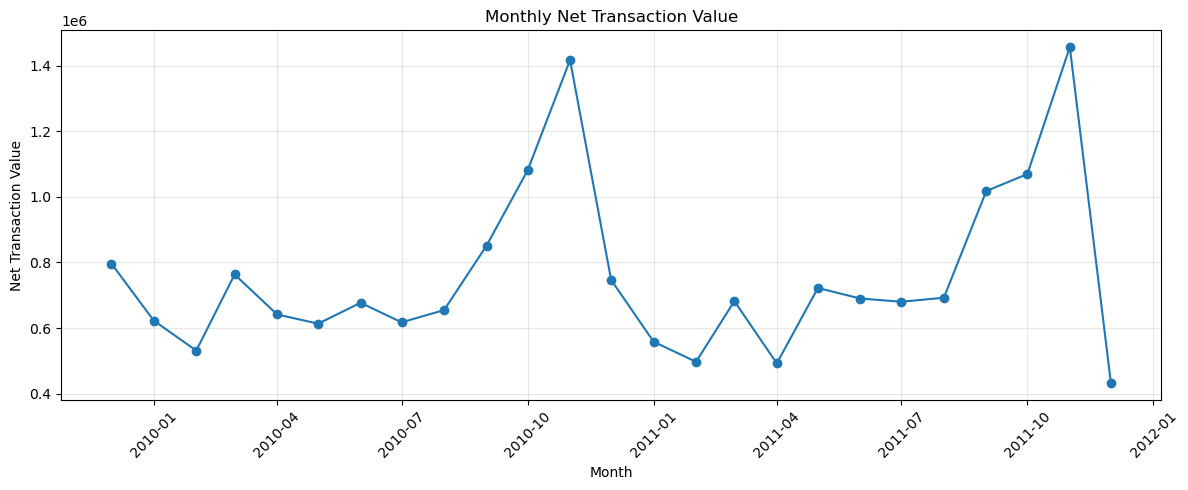

In [87]:
import matplotlib.pyplot as plt

# Group transaction lines by month
monthly_summary = (
    sales_df.assign(
        Month=sales_df["InvoiceDate"].dt.to_period("M").dt.to_timestamp()
    )
    .groupby("Month", as_index=False)
    .agg(
        Net_Transaction_Value=("Line_Value", "sum"),
        Transaction_Lines=("Invoice", "size")
    )
)

# Find the highest and lowest months
best_month = monthly_summary.loc[
    monthly_summary["Net_Transaction_Value"].idxmax()
]

worst_month = monthly_summary.loc[
    monthly_summary["Net_Transaction_Value"].idxmin()
]

print("Number of months analysed:", len(monthly_summary))

print(
    "Highest month:",
    best_month["Month"].strftime("%B %Y"),
    "| Value:",
    round(best_month["Net_Transaction_Value"], 2)
)

print(
    "Lowest month:",
    worst_month["Month"].strftime("%B %Y"),
    "| Value:",
    round(worst_month["Net_Transaction_Value"], 2)
)

display(monthly_summary)

# Plot the monthly trend
plt.figure(figsize=(12, 5))
plt.plot(
    monthly_summary["Month"],
    monthly_summary["Net_Transaction_Value"],
    marker="o"
)
plt.title("Monthly Net Transaction Value")
plt.xlabel("Month")
plt.ylabel("Net Transaction Value")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    figures_dir / "monthly_net_transaction_value.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [5]:
# Top 10 countries by net transaction value
country_summary = (
    sales_df.groupby("Country")
    .agg(
        Net_Transaction_Value = ("Line_Value", "sum"),
        Transaction_Lines = ("Invoice", "size")
    )
    .sort_values("Net_Transaction_Value", ascending = False)
)
print("Top 10 countries by net transaction value:")
display(country_summary.head(10))


# Top 10 products by net transaction value
# Standardise product codes and descriptions before grouping

product_analysis_df = sales_df.assign(
    StockCode=(
        sales_df["StockCode"]
        .astype("string")
        .str.strip()
        .str.upper()
    ),
    Description=(
        sales_df["Description"]
        .astype("string")
        .str.strip()
        .str.upper()
    )
)

product_sales_df = product_analysis_df.loc[
    product_analysis_df["Description"].notna()
    & product_analysis_df["Description"].str.strip().ne("")
    & ~product_analysis_df["Description"].str.contains(
        "POSTAGE", na=False
    )
    & ~product_analysis_df["StockCode"].isin(["DOT", "POST"])
].copy()

product_summary = (
    product_sales_df
    .groupby(
        ["StockCode", "Description"],
        dropna=False,
        as_index=False
    )
    .agg(
        Net_Transaction_Value=("Line_Value", "sum"),
        Units_Sold=("Quantity", "sum"),
        Transaction_Lines=("Invoice", "size")
    )
    .sort_values(
        "Net_Transaction_Value",
        ascending=False
    )
)

print("Top 10 products by net transaction value:")
display(product_summary.head(10))

Top 10 countries by net transaction value:


,Net_Transaction_Value,Transaction_Lines
Country,,
United Kingdom,1.613367e+07,948315
EIRE,6.099538e+05,17667
Netherlands,5.483307e+05,5137
Germany,4.119592e+05,17339
France,3.217334e+05,14025
Australia,1.664444e+05,1890
Switzerland,9.940306e+04,3175
Spain,9.101344e+04,3754
Sweden,8.777552e+04,1362


Top 10 products by net transaction value:


,StockCode,Description,Net_Transaction_Value,Units_Sold,Transaction_Lines
2197,22423,REGENCY CAKESTAND 3 TIER,314045.02,25045,4295
5666,85123A,WHITE HANGING HEART T-LIGHT HOLDER,251603.12,91026,5740
4271,47566,PARTY BUNTING,147079.73,27932,2730
5633,85099B,JUMBO BAG RED RETROSPOT,145946.05,76514,3388
5301,84879,ASSORTED COLOUR BIRD ORNAMENT,128550.42,79579,2868
1739,22086,PAPER CHAIN KIT 50'S CHRISTMAS,116298.59,34494,2084
4659,79321,CHILLI LIGHTS,79905.13,15703,1168
4860,84347,ROTATING SILVER ANGELS T-LIGHT HLDR,70969.95,22028,787
5638,85099F,JUMBO BAG STRAWBERRY,68489.89,36781,1904
3150,23084,RABBIT NIGHT LIGHT,66661.63,30631,1032


In [69]:
# Exclude transactions without an identifiable Customer ID
customer_summary = (
    sales_df.dropna(subset = ["Customer ID"])
    .groupby("Customer ID", as_index = False)
    .agg(
        Net_Transaction_Value = ("Line_Value", "sum"),
        Invoice_Count = ("Invoice", "nunique"),
        Transaction_Lines = ("Invoice", "size")
    )
    .sort_values("Net_Transaction_Value", ascending = False)
)
# Calculate the share represented by the 20% of customers
top_20_n = max(1, int(len(customer_summary) * 0.20))
identified_customer_value = customer_summary[
    "Net_Transaction_Value"
].sum()
top_20_value = customer_summary.head(top_20_n)[
    "Net_Transaction_Value"
].sum()
top_20_share = (
    top_20_value/identified_customer_value * 100
)
print("Identfied customers:", len(customer_summary))
print("Top 20% customer count:", top_20_n)
print("Top 20% net transaction value:", round(top_20_value, 2))
print("Total identified-customer net value:", 
      round(identified_customer_value, 2))
print("Share from top 20% of customers:",
     round(top_20_share, 2), "%")
display(customer_summary.head(10))
      

Identfied customers: 5942
Top 20% customer count: 1188
Top 20% net transaction value: 12607289.57
Total identified-customer net value: 16289991.29
Share from top 20% of customers: 77.39 %


,Customer ID,Net_Transaction_Value,Invoice_Count,Transaction_Lines
5756,18102.0,570380.61,153,1050
2300,14646.0,523342.07,164,3890
1810,14156.0,296063.44,202,4118
2565,14911.0,265757.91,510,11444
5104,17450.0,231390.55,61,444
1348,13694.0,190020.84,164,1551
5165,17511.0,168491.62,85,2077
69,12415.0,143269.29,33,990
4338,16684.0,141502.25,65,749
2715,15061.0,124961.98,138,909


MonthsSinceFristPurchase,0,1,2,3,4,5,6,7,8,9,10,11
CohortMonth,,,,,,,,,,,,
2009-12,100.0,35.3,33.4,42.5,38.0,35.9,37.7,34.2,33.6,36.2,42.2,49.5
2010-01,100.0,20.6,31.1,30.5,26.4,30.0,25.8,23.0,27.9,31.9,30.3,17.2
2010-02,100.0,23.8,22.5,29.1,24.6,20.1,19.3,28.6,25.4,27.5,11.5,12.6
2010-03,100.0,19.0,23.0,24.2,23.3,20.3,24.6,30.2,27.5,10.8,11.5,14.2
2010-04,100.0,19.4,19.4,16.3,18.4,22.4,27.6,26.2,10.5,10.9,7.5,13.9
2010-05,100.0,15.7,16.9,17.3,17.7,25.6,21.3,12.6,5.9,8.3,11.4,13.4
2010-06,100.0,17.4,18.9,20.4,23.0,28.5,12.6,8.9,8.1,11.9,10.7,13.7
2010-07,100.0,15.6,18.3,29.6,29.0,14.0,11.3,14.5,14.5,11.3,13.4,14.5
2010-08,100.0,20.4,29.6,32.1,17.3,11.7,9.9,12.3,13.6,13.0,13.0,12.3


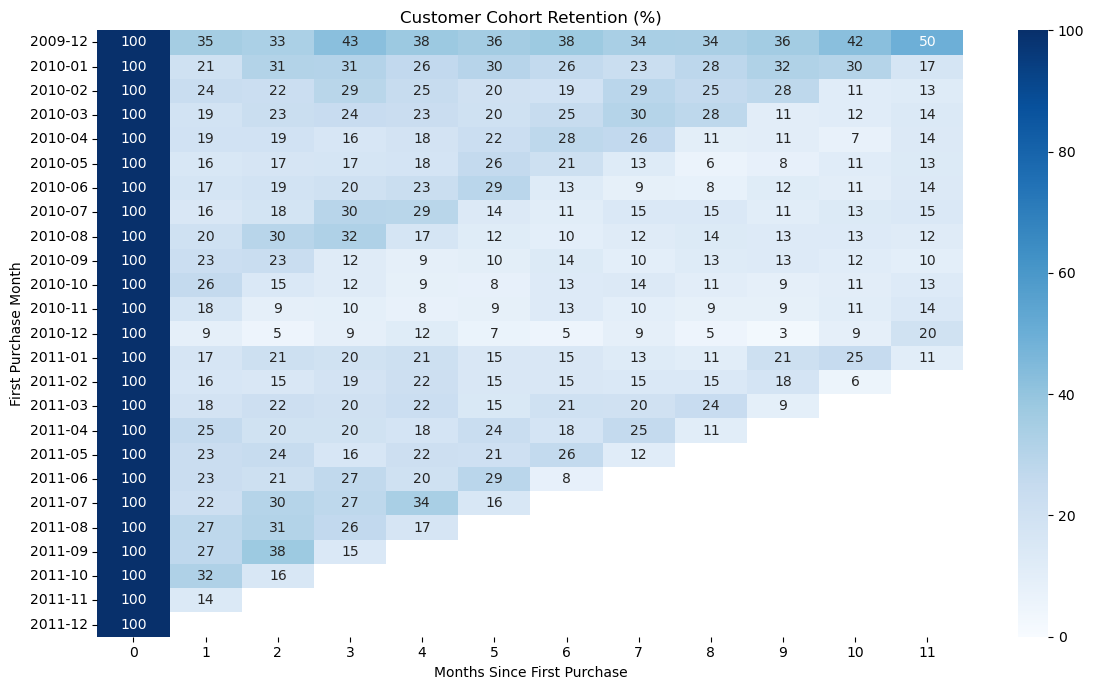

In [88]:
import matplotlib.pyplot as plt
import seaborn as sns

# Keep identifiable, positive-quantity purchase records
invoice_text = sales_df["Invoice"].astype("string")

purchase_df = sales_df.loc[
    sales_df["Customer ID"].notna()
    & ~invoice_text.str.startswith("C", na = False)
    & (sales_df["Quantity"] > 0)
    & (sales_df["Price"] > 0)
].copy()
# Identify each customer's purchase month
purchase_df["InvoiceMonth"] = (
    purchase_df["InvoiceDate"].dt.to_period("M")
)
purchase_df['CohortMonth'] = (
    purchase_df.groupby("Customer ID")["InvoiceDate"]
    .transform("min")
    .dt.to_period("M")
)
# Count distinct active customers in each cohort and month
cohort_counts = (
    purchase_df.groupby(["CohortMonth", "InvoiceMonth"])
    ["Customer ID"]
    .nunique()
    .reset_index(name = "Customers")
)

# Calculate months since 1st purchase
cohort_counts["MonthsSinceFristPurchase"] = (
    (cohort_counts["InvoiceMonth"].dt.year
    - cohort_counts["CohortMonth"].dt.year) * 12
    + cohort_counts["InvoiceMonth"].dt.month
    - cohort_counts["CohortMonth"].dt.month
)

# Create the retention table
retention_counts = cohort_counts.pivot(
    index="CohortMonth",
    columns="MonthsSinceFristPurchase",
    values="Customers"
)

cohort_sizes = retention_counts[0]

retention_rates = (
    retention_counts.div(cohort_sizes, axis=0) * 100
)

display(retention_rates.round(1).iloc[:, :12])

# Visualise customer retention
plt.figure(figsize=(12, 7))

sns.heatmap(
    retention_rates.iloc[:, :12],
    annot=True,
    fmt=".0f",
    cmap="Blues",
    vmin=0,
    vmax=100
)

plt.title("Customer Cohort Retention (%)")
plt.xlabel("Months Since First Purchase")
plt.ylabel("First Purchase Month")
plt.tight_layout()

plt.savefig(
    figures_dir / "customer_cohort_retention.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [80]:
# RFM Metrics (using identifiable, positive-price purchases)
analysis_date = (
    purchase_df["InvoiceDate"].max()
    + pd.Timedelta(days=1)
)

rfm = (
    purchase_df.groupby("Customer ID")
    .agg(
        Last_Purchase=("InvoiceDate", "max"),
        Frequency=("Invoice", "nunique"),
        Monetary=("Line_Value", "sum")
    )
    .reset_index()
)

rfm["Recency_Days"] = (
    analysis_date - rfm["Last_Purchase"]
).dt.days

print("Customers analysed:", len(rfm))
display(
    rfm.sort_values("Monetary", ascending=False).head(10)
)

Customers analysed: 5878


,Customer ID,Last_Purchase,Frequency,Monetary,Recency_Days
5692,18102.0,2011-12-09 11:50:00,145,580987.04,1
2277,14646.0,2011-12-08 12:12:00,151,528602.52,2
1789,14156.0,2011-11-30 10:54:00,156,313437.62,10
2538,14911.0,2011-12-08 15:54:00,398,291420.81,1
5050,17450.0,2011-12-01 13:29:00,51,244784.25,8
1331,13694.0,2011-12-06 09:32:00,143,195640.69,4
5109,17511.0,2011-12-07 10:12:00,60,172132.87,3
4061,16446.0,2011-12-09 09:15:00,2,168472.50,1
4295,16684.0,2011-12-05 14:06:00,55,147142.77,4
68,12415.0,2011-11-15 14:22:00,28,144458.37,24


In [81]:
# Assigning RFM scores (Score 5 means better performance within that metric)
rfm["RScore"] = pd.qcut(
    rfm["Recency_Days"].rank(method="first"),
    5,
    labels=[5, 4, 3, 2, 1]
).astype(int)

rfm["FScore"] = pd.qcut(
    rfm["Frequency"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

rfm["MScore"] = pd.qcut(
    rfm["Monetary"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

rfm["RFM_Score"] = (
    rfm["RScore"].astype(str)
    + rfm["FScore"].astype(str)
    + rfm["MScore"].astype(str)
)

display(rfm.head(10))

,Customer ID,Last_Purchase,Frequency,Monetary,Recency_Days,RScore,FScore,MScore,RFM_Score
0,12346.0,2011-01-18 10:01:00,12,77556.46,326,2,5,5,255
1,12347.0,2011-12-07 15:52:00,8,4921.53,2,5,4,5,545
2,12348.0,2011-09-25 13:13:00,5,2019.40,75,3,4,4,344
3,12349.0,2011-11-21 09:51:00,4,4428.69,19,5,3,5,535
4,12350.0,2011-02-02 16:01:00,1,334.40,310,2,1,2,212
5,12351.0,2010-11-29 15:23:00,1,300.93,375,2,1,2,212
6,12352.0,2011-11-03 14:37:00,10,2849.84,36,4,5,4,454
7,12353.0,2011-05-19 17:47:00,2,406.76,204,2,2,2,222
8,12354.0,2011-04-21 13:11:00,1,1079.40,232,2,1,3,213
9,12355.0,2011-05-09 13:49:00,2,947.61,214,2,2,3,223


In [82]:
import numpy as np

conditions = [
    # Recent, frequent and high-spending
    (
        (rfm["RScore"] >= 4)
        & (rfm["FScore"] >= 4)
        & (rfm["MScore"] >= 4)
    ),

    # Previously valuable, but not recently active
    (
        (rfm["RScore"] <= 2)
        & (
            (rfm["FScore"] >= 4)
            | (rfm["MScore"] >= 4)
        )
    ),

    # Frequent purchasers who are not Champions
    (
        (rfm["RScore"] >= 3)
        & (rfm["FScore"] >= 4)
    ),

    # High spenders with lower purchase frequency
    (
        (rfm["RScore"] >= 3)
        & (rfm["FScore"] <= 3)
        & (rfm["MScore"] >= 4)
    ),

    # Recently active, but with lower frequency
    (
        (rfm["RScore"] >= 4)
        & (rfm["FScore"] <= 2)
    )
]

segment_names = [
    "Champions",
    "At Risk - Valuable",
    "Loyal Regulars",
    "High Spend - Occasional",
    "Recent - Developing"
]

rfm["Segment"] = np.select(
    conditions,
    segment_names,
    default="Other Customers"
)

In [83]:
segment_summary = (
    rfm.groupby("Segment")
    .agg(
        Customers=("Customer ID", "nunique"),
        Avg_Recency_Days=("Recency_Days", "mean"),
        Avg_Invoices=("Frequency", "mean"),
        Total_Monetary=("Monetary", "sum")
    )
    .sort_values("Total_Monetary", ascending=False)
    .round(2)
)

segment_summary["Customer_Share_%"] = (
    segment_summary["Customers"]
    / segment_summary["Customers"].sum()
    * 100
).round(2)

display(segment_summary)

,Customers,Avg_Recency_Days,Avg_Invoices,Total_Monetary,Customer_Share_%
Segment,,,,,
Champions,1289,19.72,17.15,11819626.88,21.93
Loyal Regulars,708,83.93,7.77,1895631.38,12.04
At Risk - Valuable,526,360.98,5.96,1539666.59,8.95
Other Customers,2685,328.32,1.81,1187136.68,45.68
High Spend - Occasional,255,60.36,3.05,757157.86,4.34
Recent - Developing,415,28.36,1.44,175584.88,7.06


,Customers,Avg_Recency_Days,Avg_Invoices,Total_Monetary,Customer_Share_%,Monetary_Share_%
Segment,,,,,,
Champions,1289,19.72,17.15,11819626.88,21.93,68.03
Loyal Regulars,708,83.93,7.77,1895631.38,12.04,10.91
At Risk - Valuable,526,360.98,5.96,1539666.59,8.95,8.86
Other Customers,2685,328.32,1.81,1187136.68,45.68,6.83
High Spend - Occasional,255,60.36,3.05,757157.86,4.34,4.36
Recent - Developing,415,28.36,1.44,175584.88,7.06,1.01


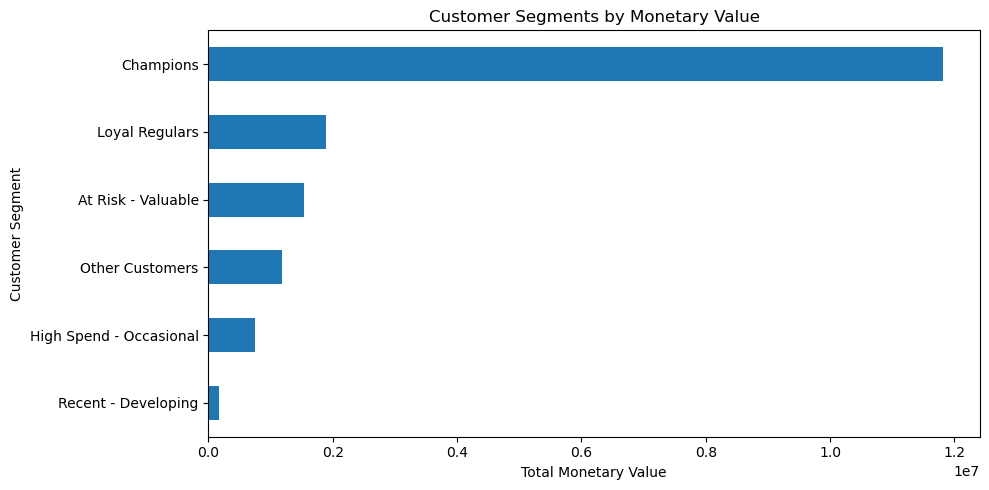

In [89]:
# Calculate each segment's share of monetary value
segment_summary["Monetary_Share_%"] = (
    segment_summary["Total_Monetary"]
    / segment_summary["Total_Monetary"].sum()
    * 100
)

# Show the final segment summary
display(
    segment_summary.sort_values(
        "Total_Monetary",
        ascending=False
    ).round(2)
)

# Plot monetary value by segment
plot_data = segment_summary.sort_values("Total_Monetary")

ax = plot_data["Total_Monetary"].plot(
    kind="barh",
    figsize=(10, 5),
    title="Customer Segments by Monetary Value"
)

ax.set_xlabel("Total Monetary Value")
ax.set_ylabel("Customer Segment")

plt.tight_layout()

plt.savefig(
    figures_dir / "customer_segments_by_monetary_value.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [86]:
figures_dir = project_root / "reports" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

print("Charts will be saved to:", figures_dir)

Charts will be saved to: /Users/khooshimangal/retail-revenue-retention-analysis/reports/figures


In [92]:
!ls -lh ../reports/figures/

total 1544
-rw-r--r--  1 khooshimangal  staff   454K 25 Oct 01:20 customer_cohort_retention.png
-rw-r--r--  1 khooshimangal  staff   117K 25 Oct 01:21 customer_segments_by_monetary_value.png
-rw-r--r--  1 khooshimangal  staff   184K 25 Oct 01:20 monthly_net_transaction_value.png


In [91]:
print("Current location:", Path.cwd())
print("Figures folder:", figures_dir)
print("Folder exists:", figures_dir.exists())

Current location: /Users/khooshimangal/retail-revenue-retention-analysis/notebooks
Figures folder: /Users/khooshimangal/retail-revenue-retention-analysis/reports/figures
Folder exists: True


In [93]:
import numpy as np
from scipy.stats import mannwhitneyu

# Calculate the value of each customer's invoice
invoice_values = (
    purchase_df.groupby(["Customer ID", "Invoice"], as_index=False)
    .agg(Order_Value=("Line_Value", "sum"))
)

# Calculate each customer's average order value
customer_aov = (
    invoice_values.groupby("Customer ID", as_index=False)
    .agg(
        Invoice_Count=("Invoice", "nunique"),
        Average_Order_Value=("Order_Value", "mean")
    )
)

customer_aov["Customer_Type"] = np.where(
    customer_aov["Invoice_Count"] == 1,
    "One-time",
    "Repeat"
)

# Compare the groups
display(
    customer_aov.groupby("Customer_Type")
    .agg(
        Customers=("Customer ID", "nunique"),
        Mean_AOV=("Average_Order_Value", "mean"),
        Median_AOV=("Average_Order_Value", "median")
    )
    .round(2)
)

one_time = customer_aov.loc[
    customer_aov["Customer_Type"] == "One-time",
    "Average_Order_Value"
]

repeat = customer_aov.loc[
    customer_aov["Customer_Type"] == "Repeat",
    "Average_Order_Value"
]

result = mannwhitneyu(
    one_time,
    repeat,
    alternative="two-sided"
)

print("Mann–Whitney U statistic:", result.statistic)
print("P-value:", result.pvalue)

,Customers,Mean_AOV,Median_AOV
Customer_Type,,,
One-time,1623,345.21,228.96
Repeat,4255,400.43,292.74


Mann–Whitney U statistic: 2793789.5
P-value: 9.102988625851425e-30


In [94]:
# Prepare a copy with SQL-friendly column names
sql_export = sales_df.drop(
    columns=["Line_Value"],
    errors="ignore"
).rename(columns={
    "Invoice": "invoice",
    "StockCode": "stock_code",
    "Description": "description",
    "Quantity": "quantity",
    "InvoiceDate": "invoice_date",
    "Price": "price",
    "Customer ID": "customer_id",
    "Country": "country"
}).copy()

# Store identifiers as text or nullable integers
sql_export["invoice"] = sql_export["invoice"].astype("string")
sql_export["stock_code"] = sql_export["stock_code"].astype("string")
sql_export["customer_id"] = (
    pd.to_numeric(sql_export["customer_id"], errors="coerce")
    .astype("Int64")
)

# Format dates for MySQL
sql_export["invoice_date"] = (
    pd.to_datetime(sql_export["invoice_date"])
    .dt.strftime("%Y-%m-%d %H:%M:%S")
)

# Export the data
csv_path = (
    project_root
    / "data"
    / "processed"
    / "retail_transactions.csv"
)

sql_export.to_csv(
    csv_path,
    index=False,
    na_rep=""
)

print("Rows exported:", len(sql_export))
print("Columns:", sql_export.columns.tolist())
print("CSV path:", csv_path)
print("File exists:", csv_path.exists())

Rows exported: 1033030
Columns: ['invoice', 'stock_code', 'description', 'quantity', 'invoice_date', 'price', 'customer_id', 'country']
CSV path: /Users/khooshimangal/retail-revenue-retention-analysis/data/processed/retail_transactions.csv
File exists: True


In [2]:
import pandas as pd
from pathlib import Path

# Find the project folder
project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent

# Reload the processed dataset
csv_path = project_root / "data" / "processed" / "retail_transactions.csv"

sales_df = pd.read_csv(
    csv_path,
    parse_dates=["invoice_date"]
)

# Restore the original column names used in our notebook
sales_df = sales_df.rename(columns={
    "invoice": "Invoice",
    "stock_code": "StockCode",
    "description": "Description",
    "quantity": "Quantity",
    "invoice_date": "InvoiceDate",
    "price": "Price",
    "customer_id": "Customer ID",
    "country": "Country"
})

# Recalculate transaction line value
sales_df["Line_Value"] = sales_df["Quantity"] * sales_df["Price"]

print("Dataset restored:", sales_df.shape)

Dataset restored: (1033030, 9)
